<a href="https://colab.research.google.com/github/juhisakshisurin/ITA0520-Computer-Vision/blob/main/Exp_29_Smile_Detection_Using_OpenCV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless

!pip install opencv-contrib-python-headless==4.14.0.94


Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Found existing installation: opencv-python-headless 5.0.0.93
Uninstalling opencv-python-headless-5.0.0.93:
  Successfully uninstalled opencv-python-headless-5.0.0.93
Found existing installation: opencv-contrib-python 4.14.0.94
Uninstalling opencv-contrib-python-4.14.0.94:
  Successfully uninstalled opencv-contrib-python-4.14.0.94
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.2/68.2 MB 55.4 MB/s  0:00:01


Saving smile_detection_input.jpg to smile_detection_input (2).jpg
Smile detected: 1


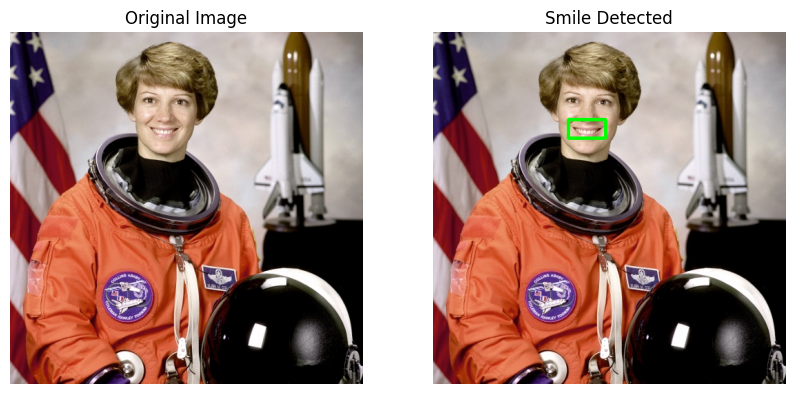

In [2]:

import cv2
import matplotlib.pyplot as plt
from google.colab import files

# Upload image
uploaded = files.upload()
filename = list(uploaded.keys())[0]

# Read image
image = cv2.imread(filename)

if image is None:
    raise ValueError("Unable to read the uploaded image.")

# Convert to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Load face detector
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

# Load smile detector
smile_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_smile.xml"
)

# Check classifiers
if face_cascade.empty() or smile_cascade.empty():
    raise RuntimeError("Unable to load Haar Cascade classifiers.")

# Detect faces
faces = face_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5
)

result = image.copy()
smile_count = 0

# Detect smiles inside each face
for (x, y, w, h) in faces:

    roi_gray = gray[y:y+h, x:x+w]
    roi_color = result[y:y+h, x:x+w]

    smiles = smile_cascade.detectMultiScale(
        roi_gray,
        scaleFactor=1.5,
        minNeighbors=15,
        minSize=(20, 10)
    )

    for (sx, sy, sw, sh) in smiles:

        cv2.rectangle(
            roi_color,
            (sx, sy),
            (sx + sw, sy + sh),
            (0, 255, 0),
            3
        )

        smile_count += 1

print("Smile detected:", smile_count)

# Display original and detected images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Smile Detected")
plt.axis("off")

plt.show()
